In [1]:
import os,sys
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import astropy
import h5py
from pathlib import Path
#import webplotdigitizer as wpd
from scipy.special import erf

%matplotlib inline
%load_ext autoreload
%autoreload 2
 
from scipy.stats import chi2 as chi2_scipy
from scipy.optimize import dual_annealing
from scipy.optimize import minimize
from scipy.integrate import quad
from math import sqrt, cos, exp, pi, sin

import matplotlib.pyplot as plt
from matplotlib import rc
from matplotlib import rcParams

from scipy.special import factorial
from scipy.special import gammaln
import math

from astropy.coordinates import SkyCoord


In [2]:
def loadFile(fileString):
    in_file = str(fileString)
    with h5py.File(in_file, 'r') as h5f:
        # Read each dataset back into memory
        ASigArray = h5f['A_sig_array'][:]
        testStat = h5f['testStat'][:]
        
    return ASigArray, testStat

# Compiling and Graphing

In [3]:
def h5_to_dict(h5_item):
    """
    Recursively walks an HDF5 object tree and converts it to a Python dict.
    """
    # If it's a Group, recurse into its keys
    if isinstance(h5_item, (h5py.File, h5py.Group)):
        return {key: h5_to_dict(h5_item[key]) for key in h5_item.keys()}
    
    # If it's a Dataset, return the actual data as a NumPy array (or scalar)
    elif isinstance(h5_item, h5py.Dataset):
        return h5_item[()]  # [()] loads the entire dataset into memory

# # Usage:
# file_path = 'your_file.h5'
# with h5py.File(file_path, 'r') as f:
#     data_dict = h5_to_dict(f)

# print(data_dict)

In [4]:
directory = Path('profiles')
yVals = np.zeros(201)
aSigArray = []
bestFitTestStats = []
mChi = []
allProfiles = []

print("Is this thing on?")

for file in directory.iterdir():
    if file.name[-7:] != "Deep.h5":
        continue

    currentDataDict = {}
    
    with h5py.File(file, 'r') as f:
        fullData = h5_to_dict(f)

    for key, value in fullData.items():
        if key == 'mChi': 
            if len(mChi) == 0:
                mChi = value

        elif key == 'bestFitTestStats':
            bestFitTestStats.append(value)

        elif key == 'A_sig_array': 
            if len(aSigArray) == 0:
                aSigArray = value

        else:
            currentDataDict.update({float(key):value})
            allProfiles.append(currentDataDict)

print("It is!")

Is this thing on?
It is!


In [5]:
allProfilesSorted = []
for profileDict in allProfiles:
    profileDictSorted = dict(sorted(profileDict.items()))
    allProfilesSorted.append(profileDictSorted)

In [6]:
#Now we have all of the data for all of the profiles. To get the plot, we need to combine them.
tauChiUpperLims = []
mChiGraphing = []

#Iterate over each lineVal
for key, value in allProfilesSorted[0].items():

    #Sum all profiles
    profileSum = np.zeros(len(value))
    for profileDict in allProfilesSorted:
        profileSum += profileDict[key]
        
    #Normalize
    profileSumNormal = profileSum - np.min(profileSum)
    
    #Find upper limit
    best_idx = np.argmin(profileSumNormal)

    upper_teststat = profileSumNormal[best_idx:]
    upper_amp = aSigArray[best_idx:]

    crossing = np.flatnonzero(upper_teststat >= 2.71)

    if len(crossing) == 0:
        limit_signal_strength = np.nan
        # print("No upper-limit crossing found")
        # print(key)

    elif crossing[0] == 0:
        limit_signal_strength = upper_amp[0]

    else:
        i = crossing[0]

        limitSignalStrength = np.interp(
            2.71,
            upper_teststat[i-1:i+1],
            upper_amp[i-1:i+1]
        )
        
    #Convert to tauChi
    tauChi = 1e25/limitSignalStrength
    tauChiUpperLims.append(tauChi)
    mChiGraphing.append(key * 2)

Text(0.5, 0, 'mChi')

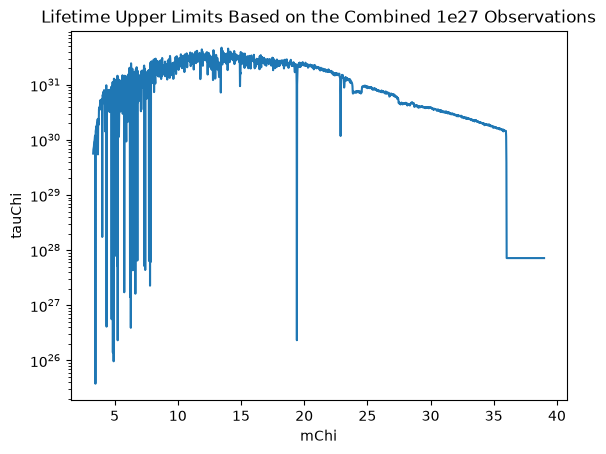

In [7]:
plt.plot(mChiGraphing, tauChiUpperLims)
plt.title('Lifetime Upper Limits Based on the Combined 1e27 Observations') 
plt.yscale('log')
plt.ylabel('tauChi')
plt.xlabel('mChi')

In [8]:
#Iterate over each lineVal
#Sum all profiles
key = 10.42
valueBase = profileDict[key]

profileSum = np.zeros(len(valueBase))
for profileDict in allProfiles:
    profileSum += profileDict[key]
        
#Normalize
profileSumNormal = profileSum - np.min(profileSum)

#Find upper limit
best_idx = np.argmin(profileSumNormal)

upper_teststat = profileSumNormal[best_idx:]
upper_amp = aSigArray[best_idx:]

crossing = np.flatnonzero(upper_teststat >= 2.71)

if len(crossing) == 0:
    limit_signal_strength = np.nan
    print("No upper-limit crossing found")

elif crossing[0] == 0:
    limit_signal_strength = upper_amp[0]

else:
    i = crossing[0]

    limitSignalStrength = np.interp(
        2.71,
        upper_teststat[i-1:i+1],
        upper_amp[i-1:i+1]
    )

#Convert to tauChi
tauChi = 1e25/limitSignalStrength
print(tauChi)

2.265833226378034e+31


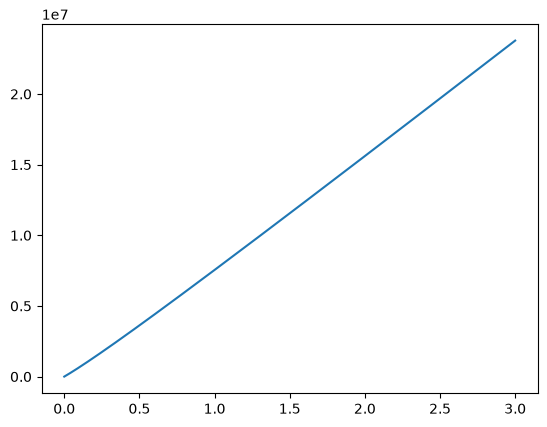

In [9]:
plt.plot(aSigArray, profileSum)

In [10]:
combinedTestStats = np.zeros(len(bestFitTestStats[0]))
for testStat in bestFitTestStats:
    combinedTestStats += testStat

Text(0.5, 0, 'mChi')

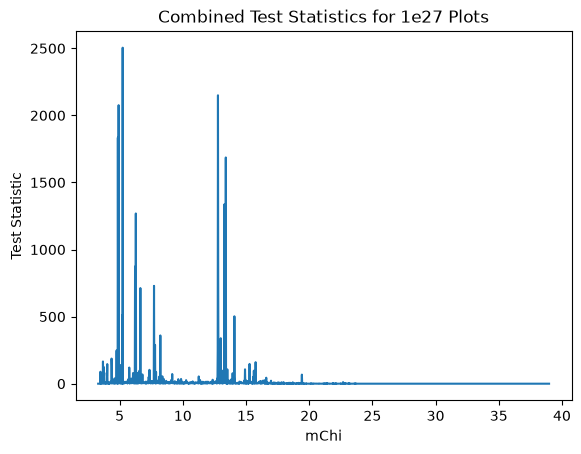

In [19]:
plt.plot(mChi, combinedTestStats)
plt.title("Combined Test Statistics for 1e27 Plots")
plt.ylabel("Test Statistic")
plt.xlabel("mChi")
# plt.xlim(19, 20)
# plt.ylim(0, 100)
#plt.yscale("log")

In [18]:
for x in range(len(mChi)):
    if mChi[x] > 19.2 and mChi[x] < 19.8 and combinedTestStats[x] > 20:
        print(combinedTestStats[x])
        print(mChi[x])

67.6094970790388
19.42
